In [ ]:
# ===== CELL 0: CONFIG =====
import os, re, json, time, hashlib, random, warnings, pickle
from pathlib import Path
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor
from collections import Counter

import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=RuntimeWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Access gate: no image is read from Drive until IT has approved this analysis.
CONFIRM_DATA_ACCESS = False

DATA_ROOT     = Path("/content/drive/MyDrive/spoof_dataset/full")
REAL_FOLDER   = "real"
SPOOF_FOLDERS = ["spoof>>>"]          # the audit prints any other folder that holds images
EXTS          = {".jpg", ".jpeg", ".png", ".webp"}

PATCH    = 256    # moire window, taken at NATIVE resolution (no resizing anywhere)
GRID     = 3      # GRID x GRID patches per frame
MIN_SIDE = PATCH  # frames with a shorter side below this are excluded and counted

INCLUDE_FACE_FEATURES = False    # face count is a cue if the spoof rule is "more than one face"
APCER_TARGET  = 0.05            # max share of spoofs accepted as real (chosen on validation)
MAX_BPCER     = 0.10            # fallback limit on genuine rejections
TEST_FOLDS    = 7               # about 14% of groups go to test
VAL_FOLDS     = 6               # about 14% of the rest go to validation
MIN_SPOOF_EVAL = 15
N_BOOT        = 1000
SEED          = 42
WORKERS       = 8

random.seed(SEED); np.random.seed(SEED)

BASE    = Path("/content/drive/MyDrive/moire_runs") if IN_COLAB else Path("./moire_runs")
RUN_DIR = BASE / f"run_{datetime.now():%Y%m%d_%H%M%S}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Run folder:", RUN_DIR, "| Colab:", IN_COLAB)


Mounted at /content/drive
Run folder: /content/drive/MyDrive/moire_runs/run_20261022_055615 | Colab: True


In [ ]:

# ============================================================
# Audit new dataset: validate face<->full pairing, readability, min size.
# Copy only PASSING face/ files to /content/local_data for fast training.
# ============================================================
def list_imgs(d):
    return sorted(p for p in Path(d).iterdir()
                  if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})

def is_valid_image(path):
    img = cv2.imread(str(path))
    if img is None: return False, "unreadable"
    h, w = img.shape[:2]
    if min(h, w) < MIN_IMG_SIDE: return False, f"too small ({w}x{h})"
    return True, None

def audit_class(face_dir, full_dir, cls_name):
    face = {p.name: p for p in list_imgs(face_dir)}
    full = {p.name: p for p in list_imgs(full_dir)}
    face_names = set(face); full_names = set(full)

    face_only = face_names - full_names
    full_only = full_names - face_names
    both      = face_names & full_names

    kept, dropped = [], []
    for name in sorted(both):
        ok, reason = is_valid_image(face[name])
        if ok:
            kept.append(face[name])
        else:
            dropped.append((name, reason))

    print(f"\n[{cls_name}]")
    print(f"  face/: {len(face)}  full/: {len(full)}  paired: {len(both)}")
    print(f"  face-only (no full): {len(face_only)}")
    print(f"  full-only (no face): {len(full_only)}")
    print(f"  kept after validity check: {len(kept)}  dropped: {len(dropped)}")
    for name, reason in dropped[:5]:
        print(f"    ✗ {name}: {reason}")
    return kept

kept_real  = audit_class(NEW_FACE_REAL,  NEW_FULL_REAL,  "REAL")
kept_spoof = audit_class(NEW_FACE_SPOOF, NEW_FULL_SPOOF, "SPOOF")

# Mirror to local disk (faster I/O than Drive)
if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)
LOCAL_FACE_REAL.mkdir(parents=True, exist_ok=True)
LOCAL_FACE_SPOOF.mkdir(parents=True, exist_ok=True)

for src in kept_real:  shutil.copy2(src, LOCAL_FACE_REAL  / src.name)
for src in kept_spoof: shutil.copy2(src, LOCAL_FACE_SPOOF / src.name)

print(f"\n✓ Local copy ready: {len(kept_real)} real + {len(kept_spoof)} spoof @ {LOCAL_ROOT}")

NameError: name 'NEW_FACE_REAL' is not defined

In [ ]:
# ==== Build local copy: full/real + full/spoof>>> (face pairing reported, not required) ====
import shutil
from pathlib import Path
from PIL import Image, ImageOps
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

ROOT  = Path("/content/drive/MyDrive/spoof_dataset")
LOCAL = Path("/content/local_data")
EXTS  = {".jpg", ".jpeg", ".png", ".webp"}
MIN_SIDE = 80                 # frames with a shorter side below this are dropped as invalid
REQUIRE_FACE_PAIR = False     # True = keep only frames that also have a face crop (old behaviour)

# class name -> (full folder, candidate face folders, label)
SOURCES = {
    "real":  ("real",     ["real"],             0),
    "spoof": ("spoof>>>", ["spoof>>>", "spoof"], 1),   # face crops may only exist under face/spoof
}

def list_imgs(d):
    return {p.stem: p for p in d.iterdir() if p.suffix.lower() in EXTS} if d.is_dir() else {}

def valid(p):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w, h = ImageOps.exif_transpose(im).size
        return min(w, h) >= MIN_SIDE
    except Exception:
        return False

def copy(pair):
    s, d = pair
    if not d.exists():
        d.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(s, d)

records = []
for cls, (full_name, face_names, y) in SOURCES.items():
    full = list_imgs(ROOT / "full" / full_name)
    face = {}
    for fn in face_names:                       # merge face crops from every candidate folder
        for k, v in list_imgs(ROOT / "face" / fn).items():
            face.setdefault(k, v)
    paired = set(full) & set(face)

    print(f"\n[{cls.upper()}]  (full/{full_name})")
    print(f"  face/: {len(face)}  full/: {len(full)}  paired: {len(paired)}")
    print(f"  face-only (no full): {len(set(face) - set(full))}")
    print(f"  full-only (no face): {len(set(full) - set(face))}")

    keys = sorted(paired) if REQUIRE_FACE_PAIR else sorted(full)
    with ThreadPoolExecutor(16) as ex:
        ok = list(tqdm(ex.map(lambda k: valid(full[k]), keys), total=len(keys), desc=f"check {cls}", leave=False))
    kept = [k for k, o in zip(keys, ok) if o]
    print(f"  kept after validity check: {len(kept)}  dropped: {len(keys) - len(kept)}")

    jobs = [(full[k], LOCAL / cls / "full" / full[k].name) for k in kept]
    jobs += [(face[k], LOCAL / cls / "face" / face[k].name) for k in kept if k in face]
    with ThreadPoolExecutor(16) as ex:
        list(tqdm(ex.map(copy, jobs), total=len(jobs), desc=f"copy {cls}", leave=False))

    for k in kept:
        records.append({"stem": k, "label": y, "cls": cls,
                        "full": str(LOCAL / cls / "full" / full[k].name),
                        "face": str(LOCAL / cls / "face" / face[k].name) if k in face else None})

n_real = sum(r["label"] == 0 for r in records); n_spoof = sum(r["label"] == 1 for r in records)
print(f"\n✓ Local copy ready: {n_real} real + {n_spoof} spoof @ {LOCAL}")


[REAL]  (full/real)
  face/: 4904  full/: 4879  paired: 4879
  face-only (no full): 25
  full-only (no face): 0


check real:   0%|          | 0/4879 [00:00<?, ?it/s]

  kept after validity check: 4879  dropped: 0


copy real:   0%|          | 0/9758 [00:00<?, ?it/s]


[SPOOF]  (full/spoof>>>)
  face/: 203  full/: 313  paired: 0
  face-only (no full): 203
  full-only (no face): 313


check spoof:   0%|          | 0/313 [00:00<?, ?it/s]

  kept after validity check: 313  dropped: 0


copy spoof:   0%|          | 0/313 [00:00<?, ?it/s]


✓ Local copy ready: 4879 real + 313 spoof @ /content/local_data


In [ ]:
# ==== Downsample REAL frames in `records` (spoof unchanged) ====
import random, collections
from pathlib import Path

N_REAL        = 300       # real frames to keep (e.g. 300, 1300, 2000)
DELETE_UNUSED = True      # also remove the dropped real copies from /content/local_data
SEED          = 42

real  = [r for r in records if r["label"] == 0]
spoof = [r for r in records if r["label"] == 1]
n_spoof_before = len(spoof)

# keep checkin/checkout of the same log together
by_log = collections.defaultdict(list)
for r in real:
    by_log[r["stem"].rsplit("_", 1)[0]].append(r)
logs = sorted(by_log)
random.Random(SEED).shuffle(logs)

real_keep = []
for lg in logs:
    if len(real_keep) >= N_REAL:
        break
    real_keep.extend(by_log[lg])
real_keep = real_keep[:N_REAL]

if DELETE_UNUSED:
    keep_paths = {r["full"] for r in real_keep} | {r["face"] for r in real_keep if r["face"]}
    removed = 0
    for r in real:
        for p in (r["full"], r["face"]):
            if p and p not in keep_paths and Path(p).exists():
                Path(p).unlink(); removed += 1
    print(f"Deleted {removed} unused real files from local disk")

records = real_keep + spoof
assert sum(r["label"] == 1 for r in records) == n_spoof_before, "Spoof count changed!"
c = collections.Counter(r["label"] for r in records)
print(f"Before: real={len(real)}  spoof={n_spoof_before}")
print(f"After : real={c[0]}  spoof={c[1]}  total={len(records)}")

Deleted 9158 unused real files from local disk
Before: real=4879  spoof=313
After : real=300  spoof=313  total=613




```
# This is formatted as code
```

## Cell 2: Cue functions

Each function reads a cue that a screen or a replay leaves in the image. All of them run on native pixels.

**Moire (the main cue).** A phone or monitor is a grid of pixels, and the camera sensor is another grid. Where the two grids interfere, a repeating pattern appears. In the 2D Fourier transform, a repeating pattern shows up as a sharp peak away from the centre. A real face photographed directly has a smooth spectrum that falls off with frequency, so its peaks stand out much less.

*Definition.* The 2D Fourier transform splits an image into the spatial frequencies it contains. Peaks away from the centre mark repeating patterns.

*Use case.* An attendance kiosk photographs a phone that shows another person's face. The screen grid and the camera grid interfere, so the spectrum has peaks that a live face does not have.

*Method.* Each 256 px patch is taken at native resolution, multiplied by a Hann window to reduce edge leakage, and transformed. The log-power is converted to a robust z-score using the median and the median absolute deviation over the frequency band. A local maximum with z above 4 counts as a peak. The features are the largest z, the peak count, the peak-to-mean power ratio, and the share of power at high frequency. Each frame has nine patches, so the image-level features are the maximum and mean over those patches.

*Caveat.* Moire depends on distance, angle and screen type. A high-resolution screen photographed close up may show little moire, so the other cues stay in the model.

**Other cues.** Sensor residual (high-pass noise), local texture (transition-based local binary pattern), glare (very bright, unsaturated pixels), colour saturation, bezel edges (long straight lines near the border), and face count.


In [ ]:
# ===== CELL 2: CUE FUNCTIONS (native resolution, no resizing) =====
def load_upright(path):
    """Full frame with EXIF rotation applied, BGR uint8. No crop, no resize."""
    with Image.open(path) as im:
        rgb = np.asarray(ImageOps.exif_transpose(im).convert("RGB"))
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

# Frequency grid for one PATCH x PATCH window, in cycles per pixel
_F = np.fft.fftshift(np.fft.fftfreq(PATCH))
_FY, _FX = np.meshgrid(_F, _F, indexing="ij")
RAD  = np.sqrt(_FX ** 2 + _FY ** 2)
# JPEG compresses in 8x8 blocks, which leaves peaks at multiples of 1/8 cycles per pixel.
# Those peaks are not moire, so they are removed from the analysis band (DC axis kept).
def _near_block_grid(F):
    k = np.round(np.abs(F) / 0.125)
    return (k >= 1) & (np.abs(np.abs(F) - k * 0.125) < 0.01)
JPEG_GRID = _near_block_grid(_FX) | _near_block_grid(_FY)
BAND = (RAD >= 0.03) & (RAD <= 0.5) & ~JPEG_GRID   # skip DC, very low and JPEG-grid frequencies
HIGH = (RAD > 0.25) & BAND
HANN = np.outer(np.hanning(PATCH), np.hanning(PATCH)).astype(np.float32)
DILATE_K = np.ones((5, 5), np.uint8)

def moire_patch(gray_patch):
    p = (gray_patch.astype(np.float32) - gray_patch.mean()) * HANN
    S = np.abs(np.fft.fftshift(np.fft.fft2(p))) ** 2
    L = np.log(S + 1e-6)
    med = np.median(L[BAND])
    mad = np.median(np.abs(L[BAND] - med)) * 1.4826 + 1e-6
    Z = np.where(BAND, (L - med) / mad, 0.0).astype(np.float32)
    peaks = (Z >= cv2.dilate(Z, DILATE_K)) & (Z > 4) & BAND
    return {
        "zmax": float(Z.max()),
        "npk4": float(peaks.sum()),
        "npk6": float(((Z > 6) & peaks).sum()),
        "peak_ratio": float(S[BAND].max() / (S[BAND].mean() + 1e-9)),
        "hf_ratio": float(S[HIGH].sum() / (S[BAND].sum() + 1e-9)),
    }

def moire_frame(gray):
    H, W = gray.shape
    ys = np.linspace(0, H - PATCH, GRID).astype(int)
    xs = np.linspace(0, W - PATCH, GRID).astype(int)
    rows = [moire_patch(gray[y:y + PATCH, x:x + PATCH]) for y in ys for x in xs]
    out = {}
    for k in ["zmax", "npk4", "npk6", "peak_ratio", "hf_ratio"]:
        v = np.array([r[k] for r in rows])
        out[f"moire_{k}_max"] = float(v.max())
        out[f"moire_{k}_mean"] = float(v.mean())
    out["moire_patch_frac"] = float(np.mean([r["zmax"] > 6 for r in rows]))
    return out

def residual_feats(gray):
    g = gray.astype(np.float32)
    hp = g - cv2.GaussianBlur(g, (0, 0), 1.5)
    s = float(hp.std()) + 1e-6
    return {"res_std": s, "res_kurt": float(np.mean((hp - hp.mean()) ** 4) / s ** 4 - 3)}

NEIGH = [(-1, -1), (-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1)]
def texture_feats(gray):
    g = gray.astype(np.int16)
    H, W = g.shape
    c = g[1:-1, 1:-1]
    bits = [g[1 + dy:H - 1 + dy, 1 + dx:W - 1 + dx] >= c for dy, dx in NEIGH]
    B = np.stack(bits, 0)
    trans = np.zeros(c.shape, np.int16)
    for k in range(8):
        trans += (B[k] != B[(k + 1) % 8])
    return {"lbp_uniform_frac": float(np.mean(trans <= 2)), "lbp_trans_mean": float(trans.mean())}

def colour_glare_feats(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    S, V = hsv[..., 1], hsv[..., 2]
    glare = ((V >= 245) & (S <= 40)).astype(np.uint8)
    n, _, stats, _ = cv2.connectedComponentsWithStats(glare, connectivity=8)
    N = glare.size
    areas = stats[1:, cv2.CC_STAT_AREA] if n > 1 else np.array([0])
    return {
        "glare_frac": float(glare.mean()),
        "glare_max_blob": float(areas.max() / N),
        "glare_blobs": float(np.sum(areas > 0.0005 * N)),
        "sat_mean": float(S.mean()), "sat_p95": float(np.percentile(S, 95)),
        "val_mean": float(V.mean()), "val_std": float(V.std()),
    }

def edge_feats(gray):
    g8 = gray.astype(np.uint8)
    H, W = g8.shape
    e = cv2.Canny(g8, 60, 150)
    tot = max(int(np.count_nonzero(e)), 1)
    bw = max(1, int(0.05 * min(H, W)))
    border = np.zeros(e.shape, bool)
    border[:bw, :] = True; border[-bw:, :] = True
    border[:, :bw] = True; border[:, -bw:] = True
    lines = cv2.HoughLinesP(e, 1, np.pi / 180, threshold=120,
                            minLineLength=int(0.4 * min(H, W)), maxLineGap=8)
    n_long, n_axis = 0, 0
    if lines is not None:
        for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
            n_long += 1
            ang = abs(np.degrees(np.arctan2(y2 - y1, x2 - x1))) % 180
            if min(ang, 180 - ang) <= 5 or abs(ang - 90) <= 5:
                n_axis += 1
    return {"edge_density": tot / e.size,
            "edge_border_frac": float(np.count_nonzero(e[border]) / tot),
            "long_lines": float(n_long),
            "axis_line_frac": float(n_axis / max(n_long, 1))}

try:
    _FACE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    if _FACE.empty():
        raise RuntimeError("empty cascade")
except Exception:
    _FACE = None
    INCLUDE_FACE_FEATURES = False
    print("WARNING: Haar face detector unavailable in this OpenCV build; face features are disabled.")

def face_feats(gray8):
    H, W = gray8.shape
    if _FACE is None:
        return {"n_faces": 0.0, "largest_face_frac": 0.0}
    faces = _FACE.detectMultiScale(gray8, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    n = len(faces)
    largest = max([int(w) * int(h) for (_, _, w, h) in faces], default=0) / float(H * W)
    return {"n_faces": float(min(n, 3)), "largest_face_frac": float(largest)}

def ahash_int(gray8):
    s = cv2.resize(gray8, (8, 8), interpolation=cv2.INTER_AREA).astype(np.float32)
    bits = (s > s.mean()).ravel().astype(np.uint64)
    return int(np.sum(bits << np.arange(64, dtype=np.uint64)))

def extract_frame(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    f = {}
    f.update(moire_frame(gray))
    f.update(residual_feats(gray))
    f.update(texture_feats(gray))
    f.update(colour_glare_feats(img))
    f.update(edge_feats(gray))
    f.update(face_feats(gray))
    f["ahash"] = f"{ahash_int(gray):016x}"
    return f

MOIRE_F  = [f"moire_{k}_{a}" for k in ["zmax", "npk4", "npk6", "peak_ratio", "hf_ratio"]
            for a in ["max", "mean"]] + ["moire_patch_frac"]
RESID_F  = ["res_std", "res_kurt"]
TEXT_F   = ["lbp_uniform_frac", "lbp_trans_mean"]
COLOUR_F = ["glare_frac", "glare_max_blob", "glare_blobs", "sat_mean", "sat_p95", "val_mean", "val_std"]
EDGE_F   = ["edge_density", "edge_border_frac", "long_lines", "axis_line_frac"]
FACE_F   = ["n_faces", "largest_face_frac"]
META_F   = ["w", "h", "short", "long", "bytes_per_px", "exif_tags", "exif_rotated"]
MAIN_F   = MOIRE_F + RESID_F + TEXT_F + COLOUR_F + EDGE_F + (FACE_F if INCLUDE_FACE_FEATURES else [])
GROUP_F  = {"moire": MOIRE_F, "residual": RESID_F, "texture": TEXT_F,
            "colour_glare": COLOUR_F, "edges": EDGE_F, "face": FACE_F}
print(f"Detector uses {len(MAIN_F)} features in {len(GROUP_F)} cue groups; metadata is excluded.")


Detector uses 26 features in 6 cue groups; metadata is excluded.


## Cell 3: Self-test on synthetic images

Before any real data is processed, this cell checks that the moire cue responds to a known pattern. A clean smooth image is compared with the same image multiplied by a 5 px screen-like grid. If the moire score does not rise for the grid, the cue is broken and the rest of the notebook should not be trusted.


In [ ]:
# ===== CELL 3: SELF-TEST ON SYNTHETIC IMAGES =====
rng_t = np.random.default_rng(0)

def natural_like(h, w):
    base = cv2.GaussianBlur(rng_t.normal(128, 40, (h, w)).astype(np.float32), (0, 0), 6)
    img = np.clip(np.dstack([base, base * 0.9, base * 0.8]), 0, 255)
    return img.astype(np.uint8)

def with_screen_moire(img, period_px=5.0, depth=0.15):
    h, w = img.shape[:2]
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    grid = 1 + depth * (np.sin(2 * np.pi * xx / period_px) * np.sin(2 * np.pi * yy / period_px))
    return np.clip(img.astype(np.float32) * grid[..., None], 0, 255).astype(np.uint8)

clean  = natural_like(480, 640)
screen = with_screen_moire(natural_like(480, 640))
a = moire_frame(cv2.cvtColor(clean, cv2.COLOR_BGR2GRAY))
b = moire_frame(cv2.cvtColor(screen, cv2.COLOR_BGR2GRAY))
print(f"clean : zmax_max={a['moire_zmax_max']:.1f}  npk4_max={a['moire_npk4_max']:.0f}")
print(f"screen: zmax_max={b['moire_zmax_max']:.1f}  npk4_max={b['moire_npk4_max']:.0f}")
assert b["moire_zmax_max"] > a["moire_zmax_max"], "moire cue does not respond to a periodic pattern"
print("OK: the moire cue responds to a synthetic screen-like pattern.")


clean : zmax_max=8.4  npk4_max=20
screen: zmax_max=12.5  npk4_max=42
OK: the moire cue responds to a synthetic screen-like pattern.


In [ ]:
# ===== FIX: build `files` for Cell 4 (works even if Cell 1 / bridge didn't run) =====
import random
from collections import Counter, defaultdict

N_REAL = 1300            # real frames to use (spoof always kept in full). None = all

# 1) header_meta() is defined in Cell 1; define it here if Cell 1 never ran
if "header_meta" not in globals():
    def header_meta(path):
        with Image.open(path) as im:
            w, h = im.size
            ex = im.getexif()
            orient = ex.get(274, 1)
            n_tags = len(ex)
        if orient in (5, 6, 7, 8):
            w, h = h, w
        return {"w": w, "h": h, "short": min(w, h), "long": max(w, h),
                "exif_rotated": orient in (5, 6, 7, 8), "exif_tags": n_tags}

# 2) Get (path, label) pairs from the best available source
if "records" in globals() and records:
    pairs = [(r["full"], int(r["label"])) for r in records]
    src = "records (local copy)"
elif Path("/content/local_data/real/full").is_dir():
    pairs  = [(str(p), 0) for p in sorted(Path("/content/local_data/real/full").iterdir()) if p.suffix.lower() in EXTS]
    pairs += [(str(p), 1) for p in sorted(Path("/content/local_data/spoof/full").iterdir()) if p.suffix.lower() in EXTS]
    src = "/content/local_data"
else:
    pairs  = [(str(p), 0) for p in sorted((DATA_ROOT / REAL_FOLDER).iterdir()) if p.suffix.lower() in EXTS]
    for sf in SPOOF_FOLDERS:
        pairs += [(str(p), 1) for p in sorted((DATA_ROOT / sf).iterdir()) if p.suffix.lower() in EXTS]
    src = f"Drive ({DATA_ROOT})"

# 3) Downsample REAL (grouped by log_id), keep ALL spoof
real  = [p for p in pairs if p[1] == 0]
spoof = [p for p in pairs if p[1] == 1]
if N_REAL is not None and len(real) > N_REAL:
    by_log = defaultdict(list)
    for p in real:
        by_log[Path(p[0]).stem.rsplit("_", 1)[0]].append(p)
    logs = sorted(by_log); random.Random(SEED).shuffle(logs)
    keep = []
    for lg in logs:
        if len(keep) >= N_REAL:
            break
        keep.extend(by_log[lg])
    real = keep[:N_REAL]

# 4) Build `files` in the exact format Cell 4 expects
files = [{"path": p, "folder": REAL_FOLDER if y == 0 else SPOOF_FOLDERS[0],
          "fname": Path(p).name, "label": y} for p, y in real + spoof]
c = Counter(f["label"] for f in files)
print(f"Source: {src}")
print(f"files ready for Cell 4 -> real={c[0]}  spoof={c[1]}  total={len(files)}")

# 5) Remove stale cached features from a different file list
if (RUN_DIR / "features.csv").exists():
    (RUN_DIR / "features.csv").unlink()
    print("Removed stale features.csv")

Source: records (local copy)
files ready for Cell 4 -> real=300  spoof=313  total=613


[link text](https://)## Cell 4: Extract features for every frame

Each frame is read once and every cue is computed on the native pixels. The results are cached to `features.csv` in the run folder. If you change `PATCH`, `GRID` or the face setting, delete that file first, or the old features will be reused.


In [ ]:
# ===== CELL 4: EXTRACT FEATURES =====
FEAT_CSV = RUN_DIR / "features.csv"

def process(job):
    try:
        img = load_upright(job["path"])
        H, W = img.shape[:2]
        if min(H, W) < MIN_SIDE:
            return {**job, "ok": False, "error": f"short side {min(H, W)} < {MIN_SIDE}"}
        row = {**job, **header_meta(job["path"]), "ok": True,
               "md5": hashlib.md5(Path(job["path"]).read_bytes()).hexdigest()}
        row["bytes_per_px"] = os.path.getsize(job["path"]) / (H * W)
        row.update(extract_frame(img))
        return row
    except Exception as e:
        return {**job, "ok": False, "error": str(e)[:120]}

if FEAT_CSV.exists():
    feats = pd.read_csv(FEAT_CSV, dtype={"ahash": str, "md5": str})
    print("Loaded cached features:", FEAT_CSV)
else:
    with ThreadPoolExecutor(WORKERS) as ex:
        rows = list(tqdm(ex.map(process, files), total=len(files), desc="features"))
    feats = pd.DataFrame(rows)
    feats.to_csv(FEAT_CSV, index=False)

ok_mask = feats.ok.astype(bool)
print(f"Usable frames: {int(ok_mask.sum())} | excluded: {int((~ok_mask).sum())}")
if (~ok_mask).any():
    print(feats[~ok_mask].groupby(["label", "error"]).size().to_string())
df = feats[ok_mask].reset_index(drop=True)
df["label"] = df.label.astype(int)
print(df.groupby("folder").label.agg(["size", "mean"]).rename(columns={"mean": "spoof_share"}).to_string())


features:   0%|          | 0/613 [00:00<?, ?it/s]

Usable frames: 582 | excluded: 31
label  error                                                                                                                   
0      OpenCV(4.14.0) /io/opencv/modules/objdetect/src/cascadedetect.hpp:46: error: (-215:Assertion failed) 0 <= scaleIdx && sc     6
       vector::_M_range_check: __n (which is 26) >= this->size() (which is 26)                                                      1
1      OpenCV(4.14.0) /io/opencv/modules/objdetect/src/cascadedetect.hpp:46: error: (-215:Assertion failed) 0 <= scaleIdx && sc    16
       operands could not be broadcast together with shapes (200,113) (256,256)                                                     5
       operands could not be broadcast together with shapes (200,200) (256,256)                                                     1
       vector::_M_range_check: __n (which is 30) >= this->size() (which is 30)                                                      2
          size  spoof_share
folder

## Cell 5: Duplicates, person/session groups, and leakage

1.   List item
2.   List item

checks

**Why this matters.** A spoof often shows an enrolled employee on a screen, and the same employee's genuine check-in may be in the dataset too. If both appear in train and test, the score measures memory of the person, not the presence of a screen.

**Groups.** Filenames like `<log_id>_checkin` and `<log_id>_checkout` are grouped by `log_id`, and each group stays in one split.

**Duplicates.** Identical files with conflicting labels are dropped. Identical files with the same label keep one copy. Near-duplicates (perceptual hash, Hamming distance at most 5) are counted across splits, so you can see whether the same photo leaks.


In [ ]:
# ===== CELL 5: DUPLICATES, GROUPS, LEAKAGE CHECKS =====
n_before = len(df)
conflict = df.groupby("md5").label.nunique()
conflict = set(conflict[conflict > 1].index)
n_conflict = int(df.md5.isin(conflict).sum())
keep = ~df.md5.isin(conflict)
sub = df[keep]
dup_idx = sub.index[sub.duplicated("md5", keep="first")]
keep.loc[dup_idx] = False
df = df[keep].reset_index(drop=True)
print(f"Rows before: {n_before} | conflicting-label rows dropped: {n_conflict} | exact duplicates dropped: {len(dup_idx)}")

SIDE_RE = re.compile(r"^(?P<log>.+)_(?P<side>checkin|checkout)$", re.IGNORECASE)
def log_of(fname):
    m = SIDE_RE.match(Path(fname).stem)
    return m["log"] if m else Path(fname).stem
df["log_id"] = df.fname.map(log_of)
n_unmatched = int((~df.fname.map(lambda f: bool(SIDE_RE.match(Path(f).stem)))).sum())
print("Filenames not matching <log>_checkin|checkout (each is its own group):", n_unmatched)

def pick_fold(idx, y, g, k):
    sgkf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=SEED)
    target_ratio, target_size = y.mean(), 1.0 / k
    return min(sgkf.split(idx, y, g),
               key=lambda f: abs(y[f[1]].mean() - target_ratio) + abs(len(f[1]) / len(y) - target_size))

y_all = df.label.values
g_all = df.log_id.values
idx_all = np.arange(len(df))
rest_rel, test_rel = pick_fold(idx_all, y_all, g_all, TEST_FOLDS)
rest, test = idx_all[rest_rel], idx_all[test_rel]
tr_rel, va_rel = pick_fold(rest, y_all[rest], g_all[rest], VAL_FOLDS)
train, val = rest[tr_rel], rest[va_rel]

df["split"] = ""
df.loc[train, "split"] = "train"
df.loc[val, "split"] = "val"
df.loc[test, "split"] = "test"
assert (df.split != "").all(), "some frames were not assigned a split"
G = {s: set(df.loc[df.split == s, "log_id"]) for s in ["train", "val", "test"]}
assert G["train"].isdisjoint(G["val"]) and G["train"].isdisjoint(G["test"]) and G["val"].isdisjoint(G["test"]), \
    "GROUP LEAKAGE across splits"
for s in ["val", "test"]:
    n_sp = int(((df.split == s) & (df.label == 1)).sum())
    assert n_sp >= MIN_SPOOF_EVAL, f"{s} has only {n_sp} spoof frames (need {MIN_SPOOF_EVAL})"

summary = (df.groupby("split").agg(frames=("label", "size"), groups=("log_id", "nunique"),
                                   real=("label", lambda s: int((s == 0).sum())),
                                   spoof=("label", lambda s: int((s == 1).sum())))
           .reindex(["train", "val", "test"]))
summary["spoof_%"] = (100 * summary.spoof / summary.frames).round(1)
print(summary.to_string())
print("No log_id appears in more than one split.")

POP8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def hash_bytes(hexes):
    v = np.array([int(h, 16) for h in hexes], dtype=np.uint64)
    return v.view(np.uint8).reshape(-1, 8)
HB = hash_bytes(df.ahash.values)

def near_dups(a, b, max_ham=5, chunk=256):
    hits = []
    for i in range(0, len(a), chunk):
        x = HB[a[i:i + chunk], None, :] ^ HB[None, b, :]
        ham = POP8[x].sum(-1)
        ii, jj = np.where(ham <= max_ham)
        hits += [(int(a[i + p]), int(b[q])) for p, q in zip(ii, jj)]
    return hits

tr_i = np.where(df.split.values == "train")[0]
va_i = np.where(df.split.values == "val")[0]
te_i = np.where(df.split.values == "test")[0]
for name, a_idx in [("val", va_i), ("test", te_i)]:
    print(f"Near-duplicate pairs (aHash Hamming<=5), {name} vs train: {len(near_dups(a_idx, tr_i))}")
df.to_csv(RUN_DIR / "splits.csv", index=False)


Rows before: 582 | conflicting-label rows dropped: 0 | exact duplicates dropped: 3
Filenames not matching <log>_checkin|checkout (each is its own group): 84
       frames  groups  real  spoof  spoof_%
split                                      
train     411     313   208    203     49.4
val        83      63    42     41     49.4
test       85      63    43     42     49.4
No log_id appears in more than one split.
Near-duplicate pairs (aHash Hamming<=5), val vs train: 34
Near-duplicate pairs (aHash Hamming<=5), test vs train: 41


## Cell 6: Shortcut gate (metadata only)

The detector does not see metadata, but metadata can still reveal the label through the way the photos were taken or saved. This gate trains a model on size, file size and EXIF fields alone. A validation AUC of 0.60 or higher means the classes differ in metadata, and the per-class size balance should be checked before trusting any result.


In [ ]:
# ===== CELL 6: METADATA SHORTCUT GATE =====
tr_d = df[df.split == "train"]
va_d = df[df.split == "val"]
gate_model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED)
gate_model.fit(tr_d[META_F].astype(float).values, tr_d.label.values)
gate_auc = roc_auc_score(va_d.label.values, gate_model.predict_proba(va_d[META_F].astype(float).values)[:, 1])
META_RISK = bool(gate_auc >= 0.60)
print(f"Metadata-only validation AUC: {gate_auc:.3f} -> {'SHORTCUT RISK' if META_RISK else 'no strong metadata shortcut'}")
print("The detector below does not use metadata. If the risk is flagged, check the per-class size table from Cell 1.")


Metadata-only validation AUC: 0.740 -> SHORTCUT RISK
The detector below does not use metadata. If the risk is flagged, check the per-class size table from Cell 1.


## Cell 7: Train, select on validation, and run the ablation

Two models are trained on the same features: a regularised logistic regression as a transparent baseline, and a gradient-boosted tree model that can use interactions between cues. Both use balanced class weights because spoofs are rare. The better model is chosen by validation PR-AUC, since PR-AUC is the metric most sensitive to spoof precision.

The ablation trains a model on each cue group alone, then on all features except that group. A group that matters should lower the score when removed. If the moire group does not help, the moire idea is not supported by this data.


In [ ]:
# ===== CELL 7: TRAIN, SELECT ON VALIDATION, ABLATION =====
def xy(split):
    d = df[df.split == split]
    return d[MAIN_F].astype(float).values, d.label.values

Xtr, ytr = xy("train")
Xva, yva = xy("val")
Xte, yte = xy("test")

def make_gbm():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                          l2_regularization=1.0, class_weight="balanced", random_state=SEED)

candidates = {
    "logreg": make_pipeline(StandardScaler(),
                            LogisticRegression(class_weight="balanced", max_iter=2000, C=1.0)),
    "hist_gbm": make_gbm(),
}
val_scores = {}
for name, est in candidates.items():
    est.fit(Xtr, ytr)
    p = est.predict_proba(Xva)[:, 1]
    val_scores[name] = {"roc_auc": roc_auc_score(yva, p), "pr_auc": average_precision_score(yva, p)}
    print(f"{name:10s} validation ROC-AUC {val_scores[name]['roc_auc']:.4f}   PR-AUC {val_scores[name]['pr_auc']:.4f}")
best_name = max(val_scores, key=lambda k: val_scores[k]["pr_auc"])
model = candidates[best_name]
print("Selected on validation PR-AUC:", best_name)

def fit_eval(cols):
    d_tr, d_va = df[df.split == "train"], df[df.split == "val"]
    m = make_gbm().fit(d_tr[cols].astype(float).values, ytr)
    p = m.predict_proba(d_va[cols].astype(float).values)[:, 1]
    return roc_auc_score(yva, p), average_precision_score(yva, p)

abl_rows = [("all main features", val_scores[best_name]["roc_auc"], val_scores[best_name]["pr_auc"])]
for gname, cols in GROUP_F.items():
    if gname == "face" and not INCLUDE_FACE_FEATURES:
        continue
    r, a_ = fit_eval(cols);                                   abl_rows.append((f"only {gname}", r, a_))
    r, a_ = fit_eval([c for c in MAIN_F if c not in cols]);   abl_rows.append((f"all minus {gname}", r, a_))
abl = pd.DataFrame(abl_rows, columns=["setting", "val_roc_auc", "val_pr_auc"])
print("\nAblation on validation:")
print(abl.round(4).to_string(index=False))
abl.to_csv(RUN_DIR / "ablation_val.csv", index=False)


logreg     validation ROC-AUC 0.9233   PR-AUC 0.8658
hist_gbm   validation ROC-AUC 0.9599   PR-AUC 0.9335
Selected on validation PR-AUC: hist_gbm

Ablation on validation:
               setting  val_roc_auc  val_pr_auc
     all main features       0.9599      0.9335
            only moire       0.8055      0.7712
       all minus moire       0.9588      0.9480
         only residual       0.8467      0.8540
    all minus residual       0.9506      0.9262
          only texture       0.7639      0.8018
     all minus texture       0.9518      0.9353
     only colour_glare       0.9326      0.9178
all minus colour_glare       0.8984      0.8780
            only edges       0.4808      0.5279
       all minus edges       0.9477      0.9340


## Cell 8: Threshold on validation, then one test evaluation

**Threshold.** On validation, the threshold is the one with the fewest genuine rejections among thresholds whose APCER is at most 5%. If no threshold reaches that target, the notebook says so and uses a fallback rule. The test set is not used to choose anything.

**Metrics.** For spoof as the positive class:
- Precision = TP / (TP + FP): of the frames flagged as spoof, the share that really are spoofs.
- Recall = TP / (TP + FN): the share of spoofs that were caught. Recall equals 1 minus APCER.
- Specificity = TN / (TN + FP): the share of genuine frames accepted. Specificity equals 1 minus BPCER.
- F1 is the harmonic mean of precision and recall.
- APCER (attack presentation classification error rate) is the share of spoofs accepted as real.
- BPCER (bona fide presentation classification error rate) is the share of genuine frames rejected as spoof.
- ACER is the average of APCER and BPCER.
- ROC-AUC and PR-AUC summarise performance across all thresholds. Brier score and expected calibration error (ECE) measure how well the probabilities match the observed frequencies.

Confidence intervals come from 1,000 bootstrap resamples, drawn separately from the spoof and genuine frames.


Threshold chosen on validation: 0.420 | APCER target met on validation

==== TEST: 43 real, 42 spoof, threshold 0.420 ====
ROC-AUC              0.9845   95% CI [0.9596, 0.9995]
PR-AUC               0.9868
Precision (spoof)       95.12%   95% CI [89.13%, 100.00%]
Recall (spoof)          92.86%   95% CI [83.33%, 100.00%]
Specificity (real)      95.35%   95% CI [88.37%, 100.00%]
F1 (spoof)              93.98%   95% CI [88.61%, 98.80%]
APCER (spoofs accepted)   7.14%   95% CI [0.00%, 16.67%]
BPCER (real rejected)    4.65%   95% CI [0.00%, 11.63%]
ACER                   5.90%
Confusion: TP=39 FN=3 FP=2 TN=41
Brier=0.0485  ECE=0.0394
With only a few dozen spoofs in test, the spoof-side intervals are wide. Read them as bounds, not point values.


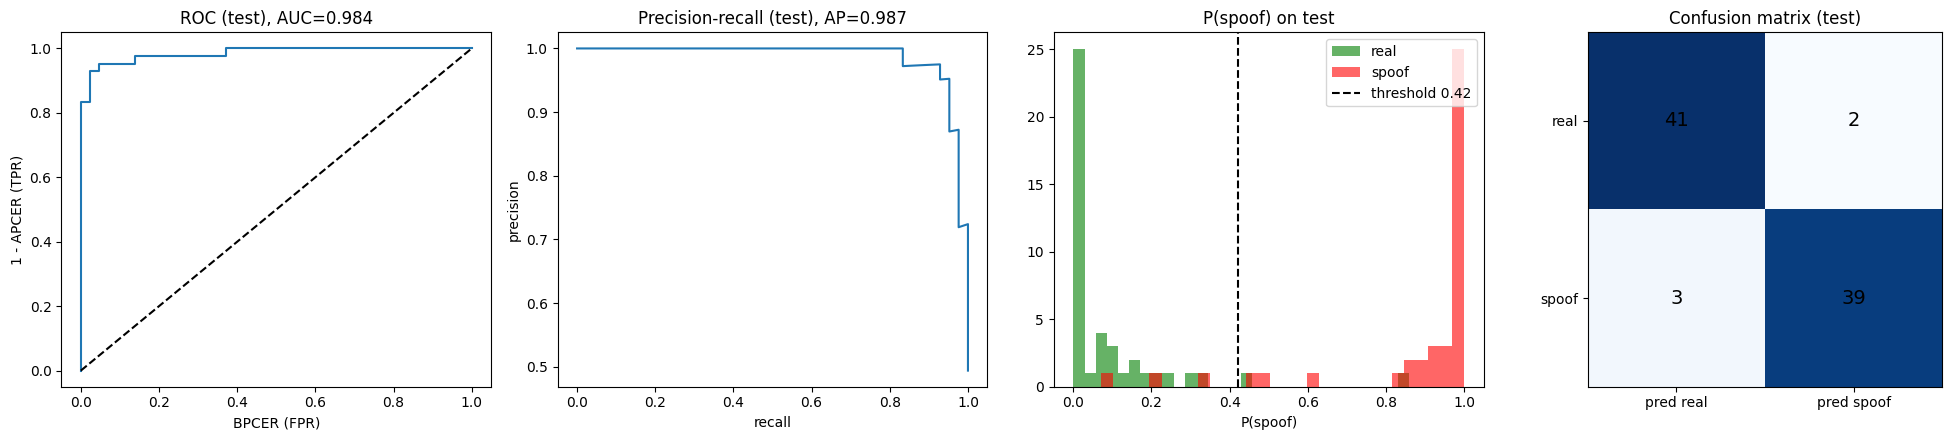

In [ ]:
# ===== CELL 8: THRESHOLD ON VALIDATION, ONE TEST EVALUATION =====
def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    def div(a, b):
        return a / b if b else float("nan")
    prec, rec, spec = div(tp, tp + fp), div(tp, tp + fn), div(tn, tn + fp)
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else float("nan")
    apcer, bpcer = div(fn, tp + fn), div(fp, fp + tn)
    return {"threshold": float(thr), "precision": prec, "recall": rec, "specificity": spec, "f1": f1,
            "accuracy": (tp + tn) / len(y), "balanced_acc": 0.5 * (rec + spec),
            "apcer": apcer, "bpcer": bpcer, "acer": 0.5 * (apcer + bpcer),
            "tp": tp, "fn": fn, "fp": fp, "tn": tn}

def pick_threshold(y, p):
    rows = [metrics_at(y, p, t) for t in np.linspace(0.005, 0.995, 199)]
    feas = [r for r in rows if r["apcer"] <= APCER_TARGET]
    if feas:
        key = min((r["bpcer"], r["apcer"]) for r in feas)
        tied = [r["threshold"] for r in feas if (r["bpcer"], r["apcer"]) == key]
        best = {"threshold": float(np.median(tied))}   # middle of the tie range, not its edge
        status = "APCER target met on validation"
    else:
        cand = [r for r in rows if r["bpcer"] <= MAX_BPCER] or rows
        best = min(cand, key=lambda r: (r["apcer"], r["bpcer"]))
        status = "APCER TARGET NOT REACHABLE on validation (fallback rule used)"
        best = {"threshold": best["threshold"]}
    return best["threshold"], status

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for i in range(bins):
        upper = (p < edges[i + 1]) if i < bins - 1 else (p <= edges[i + 1])
        m = (p >= edges[i]) & upper
        if m.any():
            total += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(total)

def bootstrap_ci(y, p, thr, n=N_BOOT):
    rng = np.random.default_rng(SEED)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keys = ["precision", "recall", "specificity", "f1", "apcer", "bpcer"]
    acc = {k: [] for k in keys + ["roc_auc"]}
    for _ in range(n):
        ib = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        m = metrics_at(y[ib], p[ib], thr)
        for k in keys:
            acc[k].append(m[k])
        acc["roc_auc"].append(roc_auc_score(y[ib], p[ib]))
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for k, v in acc.items()}

def full_report(name, y, p, thr):
    return {"set": name, "n": len(y), "n_spoof": int((y == 1).sum()), "n_real": int((y == 0).sum()),
            "roc_auc": float(roc_auc_score(y, p)), "pr_auc": float(average_precision_score(y, p)),
            "brier": float(brier_score_loss(y, p)), "ece": ece(y, p), **metrics_at(y, p, thr)}

p_va = candidates[best_name].predict_proba(Xva)[:, 1]
p_te = candidates[best_name].predict_proba(Xte)[:, 1]
THR, THR_STATUS = pick_threshold(yva, p_va)
print(f"Threshold chosen on validation: {THR:.3f} | {THR_STATUS}")

test_rep = full_report("test", yte, p_te, THR)
ci = bootstrap_ci(yte, p_te, THR)
print(f"\n==== TEST: {test_rep['n_real']} real, {test_rep['n_spoof']} spoof, threshold {THR:.3f} ====")
print(f"ROC-AUC              {test_rep['roc_auc']:.4f}   95% CI [{ci['roc_auc'][0]:.4f}, {ci['roc_auc'][1]:.4f}]")
print(f"PR-AUC               {test_rep['pr_auc']:.4f}")
for k, lab in [("precision", "Precision (spoof)"), ("recall", "Recall (spoof)"),
               ("specificity", "Specificity (real)"), ("f1", "F1 (spoof)"),
               ("apcer", "APCER (spoofs accepted)"), ("bpcer", "BPCER (real rejected)")]:
    lo, hi = ci[k]
    print(f"{lab:22s} {test_rep[k]:7.2%}   95% CI [{lo:.2%}, {hi:.2%}]")
print(f"ACER                 {test_rep['acer']:7.2%}")
print(f"Confusion: TP={test_rep['tp']} FN={test_rep['fn']} FP={test_rep['fp']} TN={test_rep['tn']}")
print(f"Brier={test_rep['brier']:.4f}  ECE={test_rep['ece']:.4f}")
print("With only a few dozen spoofs in test, the spoof-side intervals are wide. Read them as bounds, not point values.")

fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
fpr, tpr, _ = roc_curve(yte, p_te)
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set(title=f"ROC (test), AUC={test_rep['roc_auc']:.3f}", xlabel="BPCER (FPR)", ylabel="1 - APCER (TPR)")
pr_p, pr_r, _ = precision_recall_curve(yte, p_te)
ax[1].plot(pr_r, pr_p)
ax[1].set(title=f"Precision-recall (test), AP={test_rep['pr_auc']:.3f}", xlabel="recall", ylabel="precision")
ax[2].hist(p_te[yte == 0], bins=30, alpha=0.6, color="green", label="real")
ax[2].hist(p_te[yte == 1], bins=30, alpha=0.6, color="red", label="spoof")
ax[2].axvline(THR, color="k", ls="--", label=f"threshold {THR:.2f}")
ax[2].legend(); ax[2].set(title="P(spoof) on test", xlabel="P(spoof)")
cm = confusion_matrix(yte, (p_te >= THR).astype(int), labels=[0, 1])
ax[3].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[3].text(j, i, str(v), ha="center", va="center", fontsize=14)
ax[3].set_xticks([0, 1], ["pred real", "pred spoof"])
ax[3].set_yticks([0, 1], ["real", "spoof"])
ax[3].set_title("Confusion matrix (test)")
plt.tight_layout(); plt.show()


## Cell 9: Robustness, face count, feature importance, and errors

**Robustness.** A moire detector should be sensitive to the screen grid but should not collapse under ordinary image processing. Each test frame is re-processed with JPEG compression, blur, or a half-resolution round trip, and the features are recomputed. A large drop under half-resolution means the detector depends on fine detail that a deployed camera may not provide.

The **moire-only AUC** column is a model trained on moire features alone. If the full model collapses while the moire-only model holds, another cue is driving the drop. Compression-sensitive texture and residual features are the usual cause. Also note that the threshold is set on clean validation images. If APCER or BPCER jumps under a change while ROC-AUC holds, the ranking is still right but the threshold no longer transfers.

**Face count.** If the attendance rule defines a spoof as more than one face in frame, the face count is a direct cue. The table shows how often each class has one, two or three faces.

**Feature importance.** Permutation importance shuffles one feature at a time on validation and measures how much ROC-AUC falls.

**Errors.** Every misclassified test frame is listed, sorted by confidence, for manual review.


In [ ]:
# ===== CELL 9: ROBUSTNESS, FACE COUNT, IMPORTANCE, ERRORS =====
def degrade(img, kind):
    if kind == "original":
        return img
    if kind == "jpeg_q50":
        _, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 50])
        return cv2.imdecode(buf, cv2.IMREAD_COLOR)
    if kind == "blur_sigma1.5":
        return cv2.GaussianBlur(img, (0, 0), 1.5)
    if kind == "half_res_and_back":
        h, w = img.shape[:2]
        small = cv2.resize(img, (w // 2, h // 2), interpolation=cv2.INTER_AREA)
        return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    raise ValueError(kind)

te_df = df[df.split == "test"].reset_index(drop=True)

def feat_vector(path, kind):
    f = extract_frame(degrade(load_upright(path), kind))
    return [float(f[c]) for c in MAIN_F]

# Same model family trained on the moire group only, to see whether the screen cue itself survives
moire_idx = [MAIN_F.index(c) for c in MOIRE_F]
moire_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
moire_model.fit(Xtr[:, moire_idx], ytr)

print(f"{'variant':22s}{'ROC-AUC':>9s}{'APCER':>9s}{'BPCER':>9s}{'moire-only AUC':>17s}")
for kind in ["original", "jpeg_q50", "blur_sigma1.5", "half_res_and_back"]:
    with ThreadPoolExecutor(WORKERS) as ex:
        X_k = np.array(list(ex.map(lambda pth: feat_vector(pth, kind), te_df.path)), dtype=float)
    p_k = candidates[best_name].predict_proba(X_k)[:, 1]
    m_k = metrics_at(yte, p_k, THR)
    p_m = moire_model.predict_proba(X_k[:, moire_idx])[:, 1]
    print(f"{kind:22s}{roc_auc_score(yte, p_k):9.4f}{m_k['apcer']:9.1%}{m_k['bpcer']:9.1%}"
          f"{roc_auc_score(yte, p_m):17.4f}")

te_df["pred"] = (p_te >= THR).astype(int)
print("\nFace count by class (test):")
print(pd.crosstab(te_df.n_faces.astype(int).rename("faces"),
                  te_df.label.map({0: "real", 1: "spoof"})).to_string())

pi = permutation_importance(candidates[best_name], Xva, yva, scoring="roc_auc",
                            n_repeats=5, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=MAIN_F).sort_values(ascending=False)
print("\nTop features (drop in validation ROC-AUC when shuffled):")
print(imp.head(12).round(4).to_string())

wrong = (te_df.pred != te_df.label).values
err = te_df[wrong].assign(p_spoof=p_te[wrong])
err = err.sort_values("p_spoof")[["folder", "fname", "label", "p_spoof", "pred", "log_id"]]
err.to_csv(RUN_DIR / "misclassified_test.csv", index=False)
print(f"\n{len(err)} misclassified test frames -> {RUN_DIR / 'misclassified_test.csv'}")


variant                 ROC-AUC    APCER    BPCER   moire-only AUC
original                 0.9845     7.1%     4.7%           0.7829
jpeg_q50                 0.9502    19.0%     7.0%           0.7558
blur_sigma1.5            0.8128    11.9%    48.8%           0.5089
half_res_and_back        0.8837    11.9%    34.9%           0.6489

Face count by class (test):
label  real  spoof
faces             
0         5      3
1        20     27
2        13     10
3         5      2

Top features (drop in validation ROC-AUC when shuffled):
sat_mean                 0.0804
val_mean                 0.0425
lbp_uniform_frac         0.0260
res_kurt                 0.0208
glare_max_blob           0.0132
moire_hf_ratio_mean      0.0113
moire_peak_ratio_mean    0.0107
res_std                  0.0059
moire_npk4_mean          0.0056
edge_density             0.0031
moire_npk4_max           0.0022
moire_zmax_mean          0.0017

5 misclassified test frames -> /content/drive/MyDrive/moire_runs/run_20261019_0

In [ ]:
# ===== FIX: thread-safe face detection (and skip it entirely when face cues are off) =====
import threading
cv2.setNumThreads(1)                 # avoid OpenCV's own threads fighting the pool
_FACE_LOCK = threading.Lock()

def face_feats(gray8):
    if not INCLUDE_FACE_FEATURES or _FACE is None:
        return {"n_faces": 0.0, "largest_face_frac": 0.0}      # not in MAIN_F -> no effect on the model
    H, W = gray8.shape
    with _FACE_LOCK:                                           # cascade is not thread-safe
        faces = _FACE.detectMultiScale(gray8, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    n = len(faces)
    largest = max([int(w) * int(h) for (_, _, w, h) in faces], default=0) / float(H * W)
    return {"n_faces": float(min(n, 3)), "largest_face_frac": float(largest)}

print("face_feats patched | face cues in model:", INCLUDE_FACE_FEATURES)

face_feats patched | face cues in model: False


## Cell 10: Save, final report, and scoring new frames

The final table compares train, validation and test. A large gap between train and test means overfitting. The saved bundle contains the model, the feature list, the threshold and the patch settings, so the same detector can score new frames.


In [ ]:
# ===== CELL 10: SAVE, FINAL REPORT, SCORE NEW FRAMES =====
with open(RUN_DIR / "detector.pkl", "wb") as f:
    pickle.dump({"model": candidates[best_name], "features": MAIN_F, "threshold": THR,
                 "patch": PATCH, "grid": GRID, "include_face": INCLUDE_FACE_FEATURES}, f)

rep = pd.DataFrame([full_report("train", ytr, candidates[best_name].predict_proba(Xtr)[:, 1], THR),
                    full_report("val", yva, p_va, THR),
                    test_rep])
cols_show = ["set", "n", "n_spoof", "n_real", "roc_auc", "pr_auc", "precision", "recall",
             "specificity", "f1", "apcer", "bpcer", "acer", "accuracy", "brier", "ece"]
print(rep[cols_show].round(4).to_string(index=False))
rep.to_csv(RUN_DIR / "metrics_summary.csv", index=False)

decision = {"selected_model": best_name, "threshold": float(THR), "threshold_status": THR_STATUS,
            "apcer_target": APCER_TARGET, "max_bpcer": MAX_BPCER,
            "metadata_shortcut_risk": META_RISK, "metadata_gate_auc": float(gate_auc),
            "test": test_rep, "test_ci95": ci,
            "split_summary": summary.reset_index().to_dict("records")}
with open(RUN_DIR / "decision.json", "w") as f:
    json.dump(decision, f, indent=2, default=float)
print("\nSaved to", RUN_DIR)

def score_frame(path):
    img = load_upright(path)
    f = extract_frame(img)
    x = np.array([[float(f[c]) for c in MAIN_F]])
    p = float(candidates[best_name].predict_proba(x)[0, 1])
    return {"file": Path(path).name, "p_spoof": round(p, 3),
            "decision": "SPOOF" if p >= THR else "REAL", "faces": int(f["n_faces"])}

TRUE_LABELS = {}   # optional, e.g. {"2_4.jpeg": "spoof", "2_3.jpeg": "real"}
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    res = pd.DataFrame([score_frame(n) for n in uploaded])
    if TRUE_LABELS:
        res["true"] = res.file.map(TRUE_LABELS)
        lab = res[res.true.notna()]
        if len(lab):
            acc_ = (lab.true.str.lower() == lab.decision.str.lower().map({"spoof": "spoof", "real": "real"})).mean()
            print(f"Accuracy on labelled uploads: {acc_:.1%} ({len(lab)} frames)")
    print(res.to_string(index=False))
else:
    print("score_frame(path) is ready. Upload is available only in Colab.")


  set   n  n_spoof  n_real  roc_auc  pr_auc  precision  recall  specificity     f1  apcer  bpcer   acer  accuracy  brier    ece
train 411      203     208   1.0000  1.0000     1.0000  1.0000       1.0000 1.0000 0.0000 0.0000 0.0000    1.0000 0.0003 0.0115
  val  83       41      42   0.9599  0.9335     0.8511  0.9756       0.8333 0.9091 0.0244 0.1667 0.0955    0.9036 0.0729 0.0591
 test  85       42      43   0.9845  0.9868     0.9512  0.9286       0.9535 0.9398 0.0714 0.0465 0.0590    0.9412 0.0485 0.0394

Saved to /content/drive/MyDrive/moire_runs/run_20261019_070626


Saving 6ac6f22c2a92dc79eab61ad8_checkout.jpg to 6ac6f22c2a92dc79eab61ad8_checkout.jpg
Saving 6ac6f08ab6f79d1eb7fc8f0f_checkout.jpg to 6ac6f08ab6f79d1eb7fc8f0f_checkout.jpg
Saving 6a94f6628af4de03bc606e9c_checkin.jpg to 6a94f6628af4de03bc606e9c_checkin.jpg
                                 file  p_spoof decision  faces
6ac6f22c2a92dc79eab61ad8_checkout.jpg    0.981    SPOOF      0
6ac6f08ab6f79d1eb7fc8f0f_checkout.jpg    0.459    SPOOF      0
 6a94f6628af4de03bc606e9c_checkin.jpg    0.009     REAL      0


  set   n  n_spoof  n_real  roc_auc  pr_auc  precision  recall  specificity     f1  apcer  bpcer   acer  accuracy  brier    ece
train 411      203     208   1.0000  1.0000     1.0000  1.0000       1.0000 1.0000 0.0000 0.0000 0.0000    1.0000 0.0003 0.0115
  val  83       41      42   0.9599  0.9335     0.8511  0.9756       0.8333 0.9091 0.0244 0.1667 0.0955    0.9036 0.0729 0.0591
 test  85       42      43   0.9845  0.9868     0.9512  0.9286       0.9535 0.9398 0.0714 0.0465 0.0590    0.9412 0.0485 0.0394

Saved to /content/drive/MyDrive/moire_runs/run_20261019_070626


Saving 0_3.jpeg to 0_3.jpeg
Saving 6a94f6628af4de03bc606e9c_checkin.jpg to 6a94f6628af4de03bc606e9c_checkin (1).jpg
Saving 6ac6f08ab6f79d1eb7fc8f0f_checkout.jpg to 6ac6f08ab6f79d1eb7fc8f0f_checkout (1).jpg
Saving 6ac6f22c2a92dc79eab61ad8_checkout.jpg to 6ac6f22c2a92dc79eab61ad8_checkout (1).jpg
Saving 25_1.jpg to 25_1.jpg
Saving 17_.jpeg to 17_.jpeg
Saving 00abe6f9-23c3-4785-a126-933ac83d6a961757519813984.png to 00abe6f9-23c3-4785-a126-933ac83d6a961757519813984.png
                                                 file  p_spoof decision  faces
                                             0_3.jpeg    0.980    SPOOF      0
             6a94f6628af4de03bc606e9c_checkin (1).jpg    0.009     REAL      0
            6ac6f08ab6f79d1eb7fc8f0f_checkout (1).jpg    0.459    SPOOF      0
            6ac6f22c2a92dc79eab61ad8_checkout (1).jpg    0.981    SPOOF      0
                                             25_1.jpg    0.921    SPOOF      0
                                             17_.jpeg   

In [ ]:
# ===== CELL 10: SAVE, FINAL REPORT, SCORE NEW FRAMES =====
with open(RUN_DIR / "detector.pkl", "wb") as f:
    pickle.dump({"model": candidates[best_name], "features": MAIN_F, "threshold": THR,
                 "patch": PATCH, "grid": GRID, "include_face": INCLUDE_FACE_FEATURES}, f)

rep = pd.DataFrame([full_report("train", ytr, candidates[best_name].predict_proba(Xtr)[:, 1], THR),
                    full_report("val", yva, p_va, THR),
                    test_rep])
cols_show = ["set", "n", "n_spoof", "n_real", "roc_auc", "pr_auc", "precision", "recall",
             "specificity", "f1", "apcer", "bpcer", "acer", "accuracy", "brier", "ece"]
print(rep[cols_show].round(4).to_string(index=False))
rep.to_csv(RUN_DIR / "metrics_summary.csv", index=False)

decision = {"selected_model": best_name, "threshold": float(THR), "threshold_status": THR_STATUS,
            "apcer_target": APCER_TARGET, "max_bpcer": MAX_BPCER,
            "metadata_shortcut_risk": META_RISK, "metadata_gate_auc": float(gate_auc),
            "test": test_rep, "test_ci95": ci,
            "split_summary": summary.reset_index().to_dict("records")}
with open(RUN_DIR / "decision.json", "w") as f:
    json.dump(decision, f, indent=2, default=float)
print("\nSaved to", RUN_DIR)

def score_frame(path):
    img = load_upright(path)
    f = extract_frame(img)
    x = np.array([[float(f[c]) for c in MAIN_F]])
    p = float(candidates[best_name].predict_proba(x)[0, 1])
    return {"file": Path(path).name, "p_spoof": round(p, 3),
            "decision": "SPOOF" if p >= THR else "REAL", "faces": int(f["n_faces"])}

TRUE_LABELS = {}   # optional, e.g. {"2_4.jpeg": "spoof", "2_3.jpeg": "real"}
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    res = pd.DataFrame([score_frame(n) for n in uploaded])
    if TRUE_LABELS:
        res["true"] = res.file.map(TRUE_LABELS)
        lab = res[res.true.notna()]
        if len(lab):
            acc_ = (lab.true.str.lower() == lab.decision.str.lower().map({"spoof": "spoof", "real": "real"})).mean()
            print(f"Accuracy on labelled uploads: {acc_:.1%} ({len(lab)} frames)")
    print(res.to_string(index=False))
else:
    print("score_frame(path) is ready. Upload is available only in Colab.")


  set   n  n_spoof  n_real  roc_auc  pr_auc  precision  recall  specificity     f1  apcer  bpcer   acer  accuracy  brier    ece
train 411      203     208   1.0000  1.0000     1.0000  1.0000       1.0000 1.0000 0.0000 0.0000 0.0000    1.0000 0.0003 0.0115
  val  83       41      42   0.9599  0.9335     0.8511  0.9756       0.8333 0.9091 0.0244 0.1667 0.0955    0.9036 0.0729 0.0591
 test  85       42      43   0.9845  0.9868     0.9512  0.9286       0.9535 0.9398 0.0714 0.0465 0.0590    0.9412 0.0485 0.0394

Saved to /content/drive/MyDrive/moire_runs/run_20261019_070626


Saving 6ac6f08ab6f79d1eb7fc8f0f_checkout.jpg to 6ac6f08ab6f79d1eb7fc8f0f_checkout (2).jpg
Saving 6ac6f22c2a92dc79eab61ad8_checkout.jpg to 6ac6f22c2a92dc79eab61ad8_checkout (2).jpg
Saving 0_3.jpeg to 0_3 (1).jpeg
Saving 00abe6f9-23c3-4785-a126-933ac83d6a961757519813984.png to 00abe6f9-23c3-4785-a126-933ac83d6a961757519813984 (1).png
                                                     file  p_spoof decision  faces
                6ac6f08ab6f79d1eb7fc8f0f_checkout (2).jpg    0.459    SPOOF      0
                6ac6f22c2a92dc79eab61ad8_checkout (2).jpg    0.981    SPOOF      0
                                             0_3 (1).jpeg    0.980    SPOOF      0
00abe6f9-23c3-4785-a126-933ac83d6a961757519813984 (1).png    0.956    SPOOF      0


In [ ]:
# ===== CELL 10: SAVE, FINAL REPORT, SCORE NEW FRAMES =====
with open(RUN_DIR / "detector.pkl", "wb") as f:
    pickle.dump({"model": candidates[best_name], "features": MAIN_F, "threshold": THR,
                 "patch": PATCH, "grid": GRID, "include_face": INCLUDE_FACE_FEATURES}, f)

rep = pd.DataFrame([full_report("train", ytr, candidates[best_name].predict_proba(Xtr)[:, 1], THR),
                    full_report("val", yva, p_va, THR),
                    test_rep])
cols_show = ["set", "n", "n_spoof", "n_real", "roc_auc", "pr_auc", "precision", "recall",
             "specificity", "f1", "apcer", "bpcer", "acer", "accuracy", "brier", "ece"]
print(rep[cols_show].round(4).to_string(index=False))
rep.to_csv(RUN_DIR / "metrics_summary.csv", index=False)

decision = {"selected_model": best_name, "threshold": float(THR), "threshold_status": THR_STATUS,
            "apcer_target": APCER_TARGET, "max_bpcer": MAX_BPCER,
            "metadata_shortcut_risk": META_RISK, "metadata_gate_auc": float(gate_auc),
            "test": test_rep, "test_ci95": ci,
            "split_summary": summary.reset_index().to_dict("records")}
with open(RUN_DIR / "decision.json", "w") as f:
    json.dump(decision, f, indent=2, default=float)
print("\nSaved to", RUN_DIR)

def score_frame(path):
    img = load_upright(path)
    f = extract_frame(img)
    x = np.array([[float(f[c]) for c in MAIN_F]])
    p = float(candidates[best_name].predict_proba(x)[0, 1])
    return {"file": Path(path).name, "p_spoof": round(p, 3),
            "decision": "SPOOF" if p >= THR else "REAL", "faces": int(f["n_faces"])}

TRUE_LABELS = {}   # optional, e.g. {"2_4.jpeg": "spoof", "2_3.jpeg": "real"}
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    res = pd.DataFrame([score_frame(n) for n in uploaded])
    if TRUE_LABELS:
        res["true"] = res.file.map(TRUE_LABELS)
        lab = res[res.true.notna()]
        if len(lab):
            acc_ = (lab.true.str.lower() == lab.decision.str.lower().map({"spoof": "spoof", "real": "real"})).mean()
            print(f"Accuracy on labelled uploads: {acc_:.1%} ({len(lab)} frames)")
    print(res.to_string(index=False))
else:
    print("score_frame(path) is ready. Upload is available only in Colab.")


  set   n  n_spoof  n_real  roc_auc  pr_auc  precision  recall  specificity     f1  apcer  bpcer   acer  accuracy  brier    ece
train 411      203     208   1.0000  1.0000     1.0000  1.0000       1.0000 1.0000 0.0000 0.0000 0.0000    1.0000 0.0003 0.0115
  val  83       41      42   0.9599  0.9335     0.8511  0.9756       0.8333 0.9091 0.0244 0.1667 0.0955    0.9036 0.0729 0.0591
 test  85       42      43   0.9845  0.9868     0.9512  0.9286       0.9535 0.9398 0.0714 0.0465 0.0590    0.9412 0.0485 0.0394

Saved to /content/drive/MyDrive/moire_runs/run_20261019_070626


Saving 00f905c4-8f4b-4f99-bb76-64c464bd6b961786344660556.png to 00f905c4-8f4b-4f99-bb76-64c464bd6b961786344660556.png
Saving 00f14386-a4bb-45dd-8d41-a20e611baaf61785832214087.png to 00f14386-a4bb-45dd-8d41-a20e611baaf61785832214087.png
Saving 00a6bc3f-c802-42d2-9958-c49ed1dd1f531755826840724.png to 00a6bc3f-c802-42d2-9958-c49ed1dd1f531755826840724.png
Saving 00a6d65c-e0b0-42e7-a028-d56ec28c35601757420704886.png to 00a6d65c-e0b0-42e7-a028-d56ec28c35601757420704886.png
Saving 000a6bad-3ee8-4c30-909f-f33ce2128c2c1758817633817.png to 000a6bad-3ee8-4c30-909f-f33ce2128c2c1758817633817.png
Saving 00a6bbad-2339-4c49-b4d4-0ee5334b013d1757293895809.png to 00a6bbad-2339-4c49-b4d4-0ee5334b013d1757293895809.png
Saving 00a6e5e7-0702-4e82-af58-c551e8322ec71758540389402.png to 00a6e5e7-0702-4e82-af58-c551e8322ec71758540389402.png
                                                 file  p_spoof decision  faces
00f905c4-8f4b-4f99-bb76-64c464bd6b961786344660556.png    0.001     REAL      0
00f14386-a4bb-45

,n,n_real,n_spoof,roc_auc,pr_auc,precision,recall,specificity,f1,accuracy,apcer,bpcer,acer,brier,ece
set,,,,,,,,,,,,,,,
train,411,208,203,1.000,1.000,100.0%,100.0%,100.0%,1.000,100.0%,0.0%,0.0%,0.0%,0.000,0.011
val,83,42,41,0.960,0.934,85.1%,97.6%,83.3%,0.909,90.4%,2.4%,16.7%,9.6%,0.073,0.059
test,85,43,42,0.984,0.987,95.1%,92.9%,95.3%,0.940,94.1%,7.1%,4.7%,5.9%,0.048,0.039


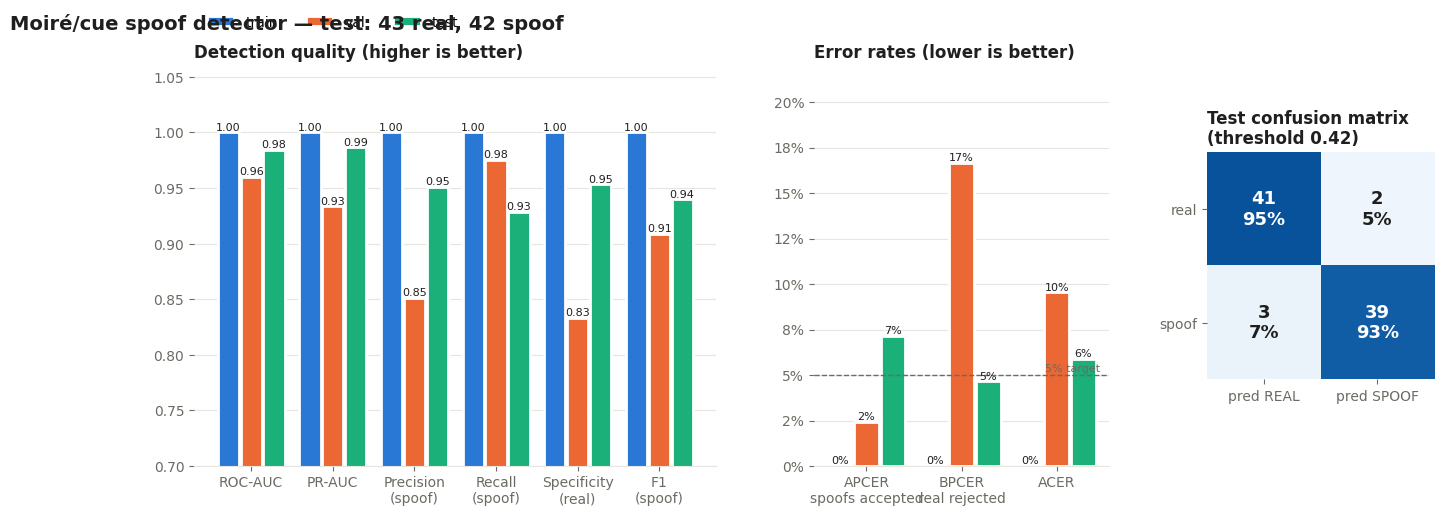

TEST  → catches 92.9% of spoofs, wrongly flags 4.7% of real employees (ACER 5.9%, ROC-AUC 0.984)
At a realistic 6% spoof share, about 56% of SPOOF flags would be correct.
Train is 1.000 AUC → memorised; judge the model on val/test only.
Saved figure → /content/drive/MyDrive/moire_runs/run_20261019_070626/eval_report.png


In [ ]:
# ===== VISUAL EVAL REPORT: styled table + metric bars + test confusion matrix =====
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from sklearn.metrics import confusion_matrix
from IPython.display import display

R = rep if "rep" in globals() else pd.read_csv(RUN_DIR / "metrics_summary.csv")
R = R.set_index("set").loc[["train", "val", "test"]]

# ---------- 1) Styled table ----------
pct  = ["precision", "recall", "specificity", "accuracy", "apcer", "bpcer", "acer"]
dec  = ["roc_auc", "pr_auc", "f1", "brier", "ece"]
good = ["roc_auc", "pr_auc", "precision", "recall", "specificity", "f1", "accuracy"]   # higher = better
bad  = ["apcer", "bpcer", "acer", "brier", "ece"]                                      # lower  = better
tbl = R[["n", "n_real", "n_spoof"] + good + bad]
styled = (tbl.style
          .format({**{c: "{:.1%}" for c in pct}, **{c: "{:.3f}" for c in dec}})
          .background_gradient(subset=good, cmap="Blues", vmin=0.8, vmax=1.0)
          .background_gradient(subset=bad, cmap="Oranges", vmin=0.0, vmax=0.2)
          .set_caption(f"Spoof detector — evaluation at threshold {THR:.3f} (chosen on validation)")
          .set_table_styles([{"selector": "caption",
                              "props": "font-size:14px; font-weight:bold; text-align:left;"}]))
display(styled)

# ---------- 2) Figure ----------
SERIES = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}   # validated categorical slots 1–3
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e6e5e0"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED})

fig = plt.figure(figsize=(16, 5.2), facecolor="white")
gs = GridSpec(1, 3, width_ratios=[2.3, 1.3, 1.0], wspace=0.28, figure=fig)

def grouped_bars(ax, cols, labels, title, ylim, as_pct):
    x = np.arange(len(cols)); w = 0.26
    for i, s in enumerate(["train", "val", "test"]):
        vals = R.loc[s, cols].astype(float).values
        bars = ax.bar(x + (i - 1) * (w + 0.02), vals, w, color=SERIES[s], label=s,
                      edgecolor="white", linewidth=2)               # 2px surface gap between bars
        for b, v in zip(bars, vals):                                # value label on every bar
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(),
                    f"{v:.0%}" if as_pct else f"{v:.2f}",
                    ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(x, labels); ax.set_ylim(*ylim)
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", color=INK)
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    for sp in ["top", "right", "left"]: ax.spines[sp].set_visible(False)
    if as_pct: ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

ax1 = fig.add_subplot(gs[0])
grouped_bars(ax1, ["roc_auc", "pr_auc", "precision", "recall", "specificity", "f1"],
             ["ROC-AUC", "PR-AUC", "Precision\n(spoof)", "Recall\n(spoof)", "Specificity\n(real)", "F1\n(spoof)"],
             "Detection quality (higher is better)", (0.7, 1.06), as_pct=False)
ax1.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.06))

ax2 = fig.add_subplot(gs[1])
grouped_bars(ax2, ["apcer", "bpcer", "acer"], ["APCER\nspoofs accepted", "BPCER\nreal rejected", "ACER"],
             "Error rates (lower is better)", (0, max(0.22, R[["apcer", "bpcer", "acer"]].values.max() * 1.25)),
             as_pct=True)
ax2.axhline(0.05, color=MUTED, ls="--", lw=1); ax2.text(2.45, 0.052, "5% target", color=MUTED, fontsize=8, ha="right")

ax3 = fig.add_subplot(gs[2])
cm = confusion_matrix(yte, (p_te >= THR).astype(int), labels=[0, 1])
ax3.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.15)
for (i, j), v in np.ndenumerate(cm):
    ax3.text(j, i, f"{v}\n{v / cm[i].sum():.0%}", ha="center", va="center", fontsize=13,
             color="white" if v > cm.max() * 0.6 else INK, fontweight="bold")
ax3.set_xticks([0, 1], ["pred REAL", "pred SPOOF"]); ax3.set_yticks([0, 1], ["real", "spoof"])
ax3.set_title(f"Test confusion matrix\n(threshold {THR:.2f})", loc="left", fontsize=12, fontweight="bold", color=INK)
for sp in ax3.spines.values(): sp.set_visible(False)

fig.suptitle(f"Moiré/cue spoof detector — test: {int(R.loc['test','n_real'])} real, "
             f"{int(R.loc['test','n_spoof'])} spoof", x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
plt.savefig(RUN_DIR / "eval_report.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- 3) Plain-language summary ----------
t = R.loc["test"]
rec, spec = t["recall"], t["specificity"]
prec6 = rec * 0.06 / (rec * 0.06 + (1 - spec) * 0.94)
print(f"TEST  → catches {rec:.1%} of spoofs, wrongly flags {1 - spec:.1%} of real employees "
      f"(ACER {t['acer']:.1%}, ROC-AUC {t['roc_auc']:.3f})")
print(f"At a realistic 6% spoof share, about {prec6:.0%} of SPOOF flags would be correct.")
print(f"Train is {R.loc['train','roc_auc']:.3f} AUC → memorised; judge the model on val/test only.")
print(f"Saved figure → {RUN_DIR / 'eval_report.png'}")

In [ ]:
# ==== F1: LOAD FACE-CROPPED DATASET (real + spoof) -> train/val/test ====
from google.colab import drive; drive.mount('/content/drive')
import cv2, numpy as np, torch, torch.nn as nn, collections, random, shutil
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

FACE_ROOT    = Path("/content/drive/MyDrive/spoof_dataset/face")
LOCAL        = Path("/content/face_local")
CLASSES      = {"real": 0, "spoof": 1}          # face/spoof = 203 crops (old spoof labels)
EXTS         = {".jpg", ".jpeg", ".png", ".webp"}
IMG_SIZE     = 224                               # same as the original model
N_REAL_TRAIN = 1000                              # real crops kept in TRAIN (~4:1). None = all
SEED         = 42
DEVICE       = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "Switch runtime to GPU (Runtime > Change runtime type > T4)"

# 1) copy crops locally (fast reads during training) + record sizes
def copy_one(pair):
    s, d = pair
    try:
        if not d.exists(): shutil.copy2(s, d)
        with Image.open(d) as im: return im.size
    except Exception:
        return None

records, sizes = [], {0: [], 1: []}
for cls, y in CLASSES.items():
    out = LOCAL / cls; out.mkdir(parents=True, exist_ok=True)
    pairs = [(p, out / p.name) for p in sorted((FACE_ROOT / cls).iterdir()) if p.suffix.lower() in EXTS]
    with ThreadPoolExecutor(16) as ex:
        res = list(tqdm(ex.map(copy_one, pairs), total=len(pairs), desc=f"face/{cls}"))
    for (s, d), sz in zip(pairs, res):
        if sz: records.append((str(d), y)); sizes[y].append(sz)

for y, n in [(0, "real"), (1, "spoof")]:
    s = np.array([min(w, h) for w, h in sizes[y]])
    print(f"{n:5s}: {len(s):5d} crops | crop side median {int(np.median(s))}px | "
          f"<112px: {np.mean(s < 112):.0%} | upscaled to 224: {np.mean(s < IMG_SIZE):.0%}")

# 2) split by log_id (checkin/checkout together): ~70% train / 15% val / 15% test
labels = np.array([y for _, y in records])
groups = np.array([Path(p).stem.rsplit("_", 1)[0] for p, _ in records])
idx = np.arange(len(records))
rest, test = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED).split(idx, labels, groups))
tr_rel, va_rel = next(StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
                      .split(rest, labels[rest], groups[rest]))
train, val = rest[tr_rel], rest[va_rel]
assert set(groups[train]).isdisjoint(groups[val]) and set(groups[train]).isdisjoint(groups[test]) \
       and set(groups[val]).isdisjoint(groups[test]), "GROUP LEAKAGE"

train_items = [records[i] for i in train]
val_items   = [records[i] for i in val]
test_items  = [records[i] for i in test]

# 3) downsample REAL in TRAIN only (val/test keep realistic proportions)
if N_REAL_TRAIN is not None:
    rng = random.Random(SEED)
    tr_real  = [r for r in train_items if r[1] == 0]
    tr_spoof = [r for r in train_items if r[1] == 1]
    train_items = rng.sample(tr_real, min(N_REAL_TRAIN, len(tr_real))) + tr_spoof

for name, items in [("train", train_items), ("val", val_items), ("test", test_items)]:
    c = collections.Counter(y for _, y in items)
    print(f"{name:5s}: real={c[0]:5d}  spoof={c[1]:4d}")

In [ ]:
# ==== F2: DATASET + LOADERS + LOAD ORIGINAL FACE MODEL ====
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

class FaceCropDataset(Dataset):
    """Same preprocessing as the original model: BGR, resize 224, scale to [-1, 1]."""
    def __init__(self, items, augment=False):
        self.items, self.augment = items, augment
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        img = cv2.imread(path)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        if self.augment:                                   # mild: keep texture/colour cues intact
            if np.random.rand() < 0.5: img = cv2.flip(img, 1)
            if np.random.rand() < 0.4:
                img = cv2.convertScaleAbs(img, alpha=np.random.uniform(0.85, 1.15), beta=np.random.uniform(-12, 12))
            if np.random.rand() < 0.3:
                M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), np.random.uniform(-8, 8), 1.0)
                img = cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT)
        img = img.astype(np.float32) / 127.5 - 1.0
        return torch.from_numpy(img.transpose(2, 0, 1)), y

tc = collections.Counter(y for _, y in train_items)
sampler = WeightedRandomSampler([1.0 / tc[y] for _, y in train_items],
                                num_samples=len(train_items), replacement=True)   # ~50/50 batches
train_loader = DataLoader(FaceCropDataset(train_items, augment=True), batch_size=32, sampler=sampler,
                          num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(FaceCropDataset(val_items),  batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(FaceCropDataset(test_items), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

class MiniFASNetV2_Fixed(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = self._ds_conv(3, 8, 3, 1, 1)
        self.conv2 = self._ds_conv(8, 16, 3, 2, 1)
        self.conv3 = self._ds_conv(16, 32, 3, 1, 1)
        self.conv4 = self._ds_conv(32, 64, 3, 2, 1)
        self.conv5 = self._ds_conv(64, 128, 3, 1, 1)
        self.conv6 = self._ds_conv(128, 256, 3, 2, 1)
        self.conv7 = self._ds_conv(256, 256, 3, 1, 1)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(256, 128)
        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, num_classes)
    def _ds_conv(self, in_c, out_c, k, s, p):
        return nn.Sequential(
            nn.Conv2d(in_c, in_c, k, s, p, groups=in_c, bias=False),
            nn.BatchNorm2d(in_c), nn.ReLU(inplace=True),
            nn.Conv2d(in_c, out_c, 1, 1, 0, bias=False),
            nn.BatchNorm2d(out_c), nn.ReLU(inplace=True))
    def forward(self, x):
        for b in [self.conv1, self.conv2, self.conv3, self.conv4, self.conv5, self.conv6, self.conv7]:
            x = b(x)
        x = self.avgpool(x).view(x.size(0), -1)
        return self.fc2(self.dropout(self.relu(self.fc1(x))))

# ---- Start from the ORIGINAL face model (handles plain state_dict or {"state_dict": ...}) ----
START_CKPT = "/content/drive/MyDrive/checkpoints/best_model.pth"
# START_CKPT = "/content/drive/MyDrive/checkpoints_full/best_full_model.pth"   # comparison run only
raw = torch.load(START_CKPT, map_location=DEVICE, weights_only=False)
state = raw["state_dict"] if isinstance(raw, dict) and "state_dict" in raw else raw
model = MiniFASNetV2_Fixed(num_classes=2).to(DEVICE)
model.load_state_dict(state)
print(f"Loaded start checkpoint: {START_CKPT}")

# ---- Baseline BEFORE fine-tuning (validation) ----
from sklearn.metrics import roc_auc_score
@torch.no_grad()
def predict(m, loader):
    m.eval(); P, Y = [], []
    for x, y in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            P.append(torch.softmax(m(x.to(DEVICE)).float(), 1)[:, 1].cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

p, y = predict(model, val_loader); pred = (p >= 0.5).astype(int)
real_acc, spoof_acc = (pred[y == 0] == 0).mean(), (pred[y == 1] == 1).mean()
print(f"Baseline on face val -> AUC {roc_auc_score(y, p):.4f} | real {real_acc:.1%} | spoof {spoof_acc:.1%} "
      f"| BAcc {(real_acc + spoof_acc) / 2:.1%}")

Loaded start checkpoint: /content/drive/MyDrive/checkpoints/best_model.pth
Baseline on face val -> AUC 0.7587 | real 87.7% | spoof 47.1% | BAcc 67.4%


In [ ]:
# ==== F3: FINE-TUNE ON FACE CROPS (saves to checkpoints_face/) ====
import torch.optim as optim, json
from sklearn.metrics import roc_curve

OUT_DIR = Path("/content/drive/MyDrive/checkpoints_face"); OUT_DIR.mkdir(exist_ok=True)
BEST, LATEST, HIST = OUT_DIR / "best_face_model.pth", OUT_DIR / "latest_face_model.pth", OUT_DIR / "history.json"

EPOCHS, WARMUP, PATIENCE = 30, 3, 7
FROZEN = ["conv1", "conv2", "conv3", "conv4", "conv5"]
bb_params   = [p for n, p in model.named_parameters() if n.split(".")[0] in FROZEN]
head_params = [p for n, p in model.named_parameters() if n.split(".")[0] not in FROZEN]

optimizer = optim.AdamW([{"params": bb_params, "lr": 2e-5}, {"params": head_params, "lr": 1e-4}], weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)        # sampler already balances classes
scaler    = torch.amp.GradScaler("cuda")

def metrics(p, y, thr=0.5):
    pred = (p >= thr).astype(int)
    real, spoof = float((pred[y == 0] == 0).mean()), float((pred[y == 1] == 1).mean())
    return {"auc": float(roc_auc_score(y, p)), "real": real, "spoof": spoof, "bacc": (real + spoof) / 2, "thr": float(thr)}

def tuned_thr(p, y):
    fpr, tpr, t = roc_curve(y, p); return float(min(t[np.argmax(tpr - fpr)], 1.0))

history = collections.defaultdict(list)
best_auc, bad = 0.0, 0
for epoch in range(1, EPOCHS + 1):
    frozen = epoch <= WARMUP
    for p_ in bb_params: p_.requires_grad = not frozen
    model.train()
    if frozen:
        for b in FROZEN: getattr(model, b).eval()               # keep pretrained BN stats

    tot, cor, n = 0.0, 0, 0
    for x, yb in tqdm(train_loader, desc=f"Ep {epoch} [{'head' if frozen else 'full'}]", leave=False):
        x, yb = x.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(x); loss = criterion(out, yb)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        scaler.step(optimizer); scaler.update()
        tot += loss.item() * x.size(0); n += x.size(0); cor += (out.argmax(1) == yb).sum().item()
    scheduler.step()

    p, yv = predict(model, val_loader)
    m, mt = metrics(p, yv), metrics(p, yv, tuned_thr(p, yv))
    for k, v in {"loss": tot / n, "acc": cor / n, **{f"val_{k}": v for k, v in m.items()},
                 "val_bacc_tuned": mt["bacc"], "thr_tuned": mt["thr"]}.items():
        history[k].append(float(v))
    print(f"Ep {epoch:2d} | loss {tot/n:.4f} acc {cor/n:.1%} | AUC {m['auc']:.4f} | "
          f"at 0.5 real {m['real']:.1%} spoof {m['spoof']:.1%} | at {mt['thr']:.2f} BAcc {mt['bacc']:.1%}")

    torch.save(model.state_dict(), LATEST); json.dump(history, open(HIST, "w"), indent=2)
    if m["auc"] > best_auc + 0.001:
        best_auc, bad = m["auc"], 0
        torch.save({"state_dict": model.state_dict(), "threshold": mt["thr"], "epoch": epoch,
                    "metrics": mt, "start_ckpt": START_CKPT, "img_size": IMG_SIZE}, BEST)
        print(f"   ✓ best saved (AUC {best_auc:.4f}, thr {mt['thr']:.3f}) -> {BEST}")
    elif not frozen:
        bad += 1
        if bad >= PATIENCE:
            print(f"Early stop at epoch {epoch}"); break

print(f"\nDONE - best val AUC {best_auc:.4f} | files in {OUT_DIR}:")
for f in sorted(OUT_DIR.iterdir()):
    print(f"   {f.name:25s} {f.stat().st_size/1024:8.1f} KB")

In [ ]:
# ===== USAGE 1: LOAD SAVED DETECTOR (no retraining) =====
# Needs: Cell 0 (config) + Cell 2 (cue functions) + face-fix cell run first in this session.
import pickle
DETECTOR = Path("/content/drive/MyDrive/moire_runs/run_20261019_070626/detector.pkl")
with open(DETECTOR, "rb") as f:
    B = pickle.load(f)
det_model, DET_F, DET_THR = B["model"], B["features"], B["threshold"]
assert B["patch"] == PATCH and B["grid"] == GRID, f"PATCH/GRID mismatch: saved {B['patch']}/{B['grid']}"
assert all(c in MAIN_F for c in DET_F), "feature list differs from Cell 2"
print(f"Loaded {type(det_model).__name__} | {len(DET_F)} features | threshold {DET_THR:.3f} | from {DETECTOR}")

def score_frame(path, thr=DET_THR):
    img = load_upright(path)
    if min(img.shape[:2]) < PATCH:
        return {"file": Path(path).name, "p_spoof": None, "decision": f"TOO SMALL (<{PATCH}px)"}
    f = extract_frame(img)
    x = np.nan_to_num(np.array([[float(f[c]) for c in DET_F]]))
    p = float(det_model.predict_proba(x)[0, 1])
    return {"file": Path(path).name, "p_spoof": round(p, 3), "decision": "SPOOF" if p >= thr else "REAL"}

print("score_frame(path) ready.")

Loaded HistGradientBoostingClassifier | 26 features | threshold 0.420 | from /content/drive/MyDrive/moire_runs/run_20261019_070626/detector.pkl
score_frame(path) ready.


In [ ]:
# ===== USAGE 2: UPLOAD IMAGES AND SCORE =====
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()
res = pd.DataFrame([score_frame(n) for n in uploaded])
print(res.to_string(index=False))
if len(res):
    n = len(res); cols = min(4, n); rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, (_, r) in zip(axes.flat, res.iterrows()):
        ax.imshow(cv2.cvtColor(load_upright(r["file"]), cv2.COLOR_BGR2RGB))
        col = "red" if r["decision"] == "SPOOF" else ("green" if r["decision"] == "REAL" else "gray")
        ax.set_title(f"{r['decision']}\np(spoof)={r['p_spoof']}", color=col, fontweight="bold")
    plt.tight_layout(); plt.show()